In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.sparse import issparse
from scipy.stats import mannwhitneyu
import scanpy as sc
import tqdm
import functools
import glob
import gzip as gz
import itertools
import math
import os
import sys
from importlib import reload

sys.path.append('/Genomics/pritykinlab/dillon/perturbseq/scripts/utils')
import misc

In [2]:
plt.rcParams["axes.titlesize"] = 25
plt.rcParams["axes.labelsize"] = 25
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20
plt.rcParams["lines.markersize"] = 5
plt.rcParams['axes.grid'] = False
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['ytick.major.size'] = 5
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.title_fontsize'] = 15
plt.rcParams['legend.edgecolor'] = 'dimgray'
plt.rcParams['figure.figsize'] = (7,7)

# Initial Processing and Filtering Out cells

In [82]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/02_LP.h5ad")

In [83]:
reload(misc)
adata = misc.score_cell_cycle_genes(adata)

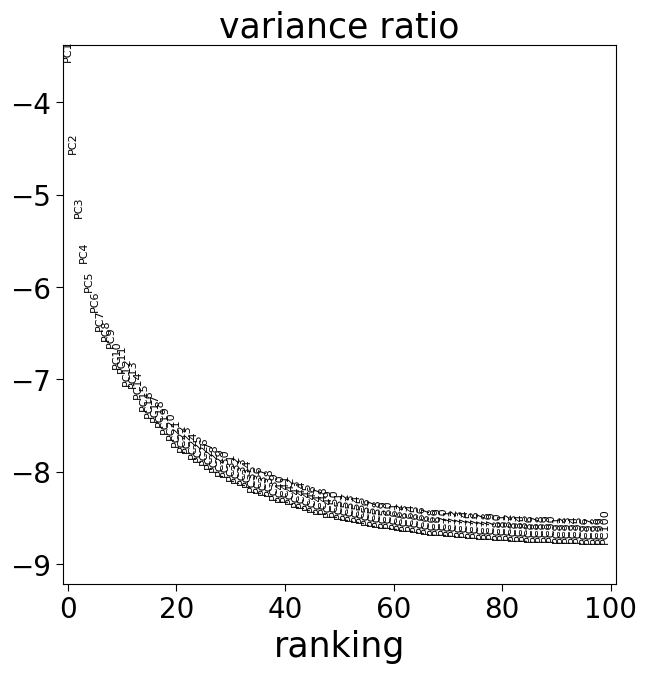

In [84]:
adata.raw = adata
adata.X = adata.X.toarray()
sc.pp.normalize_total(adata, exclude_highly_expressed=True)
adata.layers['norm'] = adata.X.copy()
sc.pp.log1p(adata)
adata.layers['norm_log'] = adata.X.copy()
sc.pp.scale(adata, max_value=10)
adata.layers['norm_log_zscore'] = adata.X.copy()
sc.tl.pca(adata, svd_solver='arpack', n_comps=100)
sc.pl.pca_variance_ratio(adata, n_pcs=100, log=True)

In [85]:
sc.pp.neighbors(adata, n_neighbors=20, n_pcs=75)
sc.tl.umap(adata)

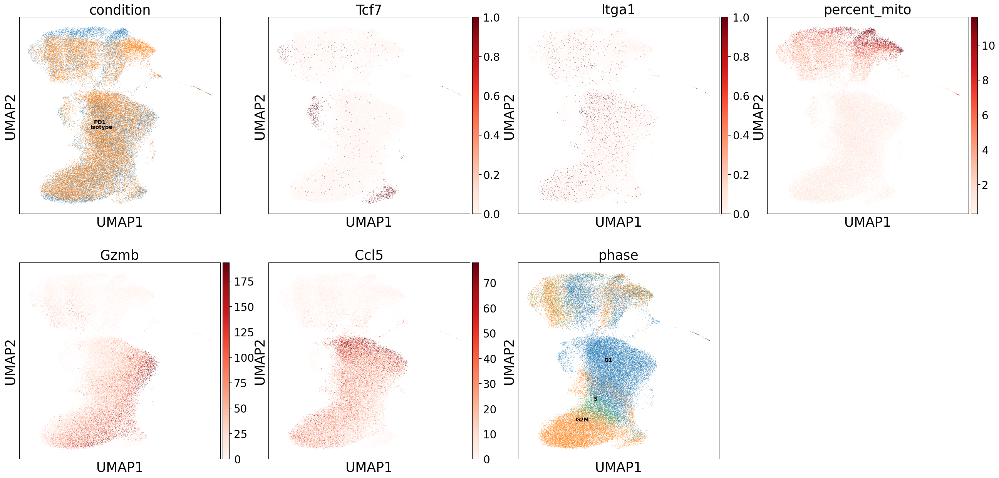

In [183]:
plt.rcParams['figure.figsize'] = (7,7)
sc.pl.umap(adata, color=['condition', 'Tcf7', 'Itga1', 'percent_mito', 'Gzmb', 'Ccl5', 'phase'],
           legend_loc='on data', cmap='Reds', vmin="p2", vmax="p98")

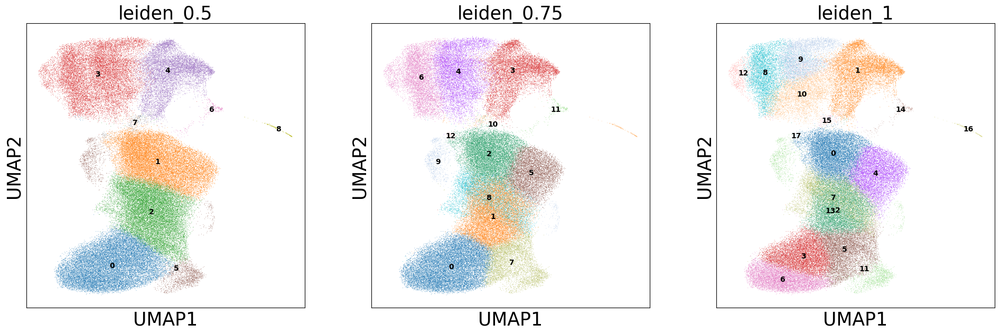

############################ leiden_0.5 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8


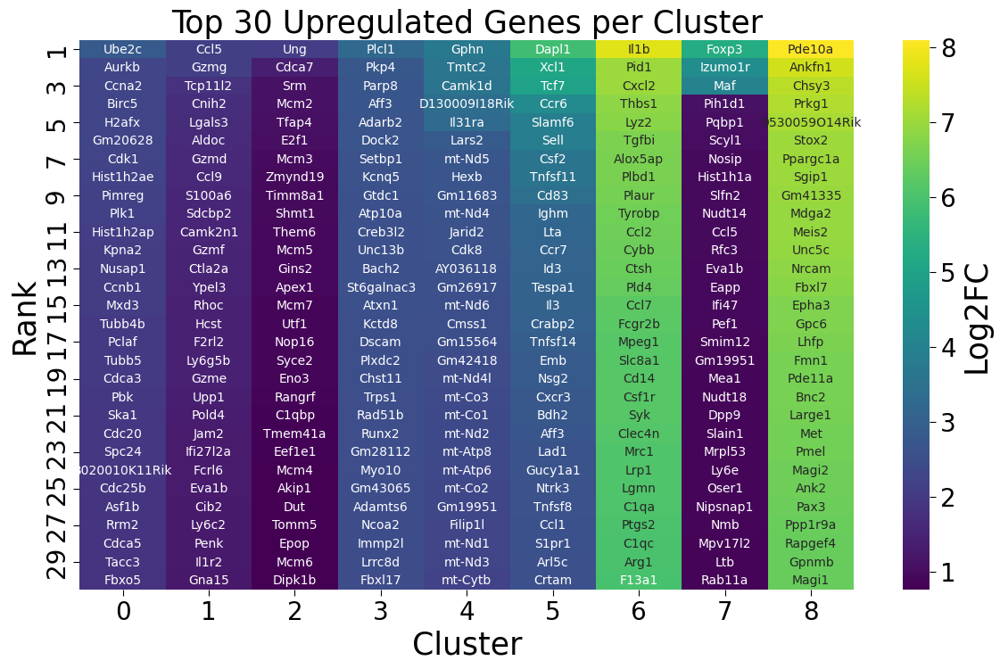

############################ leiden_0.75 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12


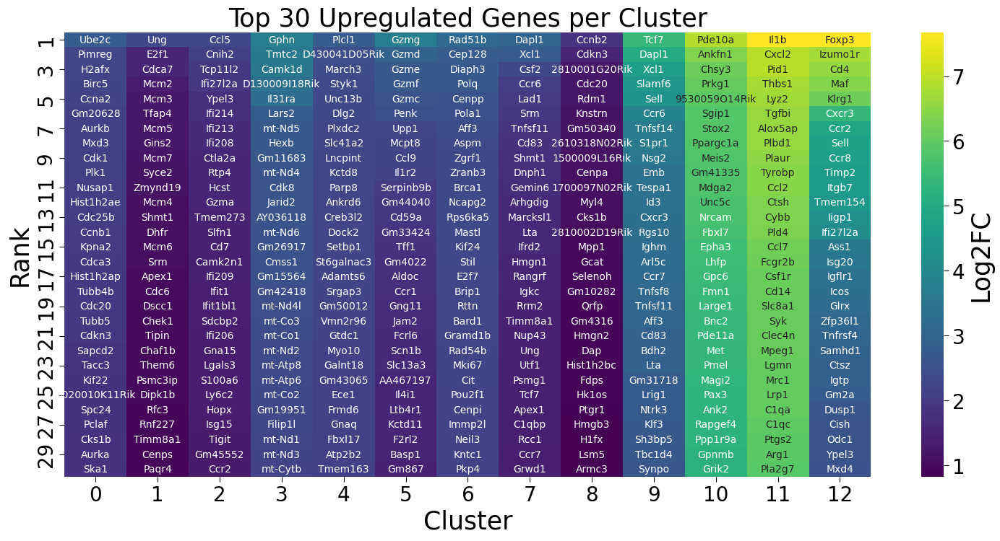

############################ leiden_1 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12
Processing cluster 13
Processing cluster 14
Processing cluster 15
Processing cluster 16
Processing cluster 17


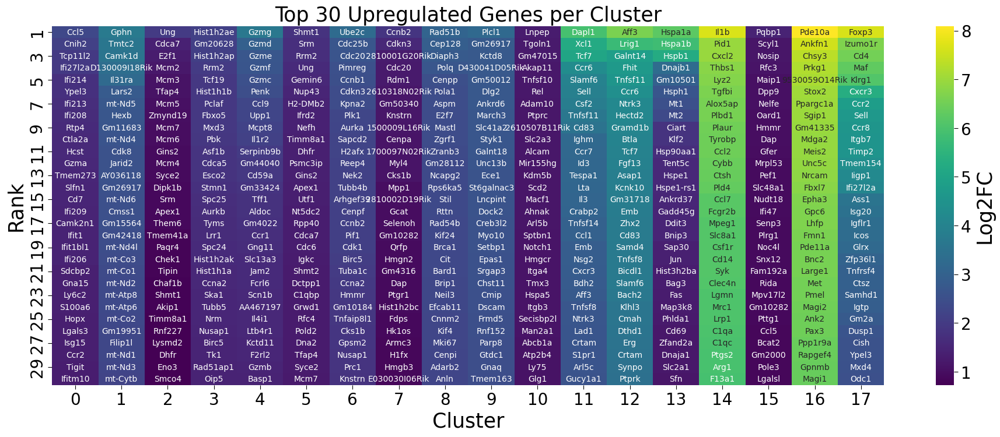

In [87]:
import DE_testing
reload(DE_testing)
all_de_results = DE_testing.apply_multi_resolution_clustering_then_heatmaps(adata, [0.5, 0.75, 1])

In [88]:
# adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/03_filter_cells_adata.h5ad")

# Remove bad cells
- high mito/non CD8+ T cells

In [177]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/03_filter_cells_adata.h5ad")

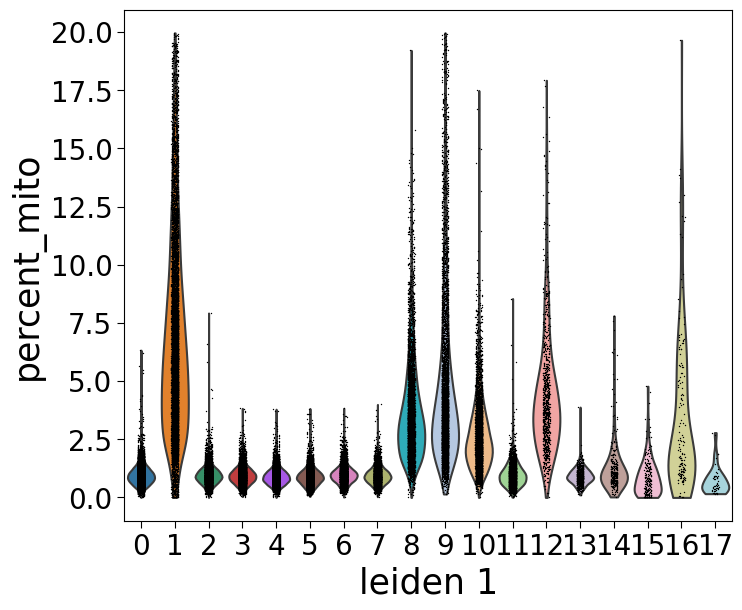

In [178]:
sc.pl.violin(adata, keys='percent_mito', groupby='leiden_1', layer='norm_log', use_raw=False)

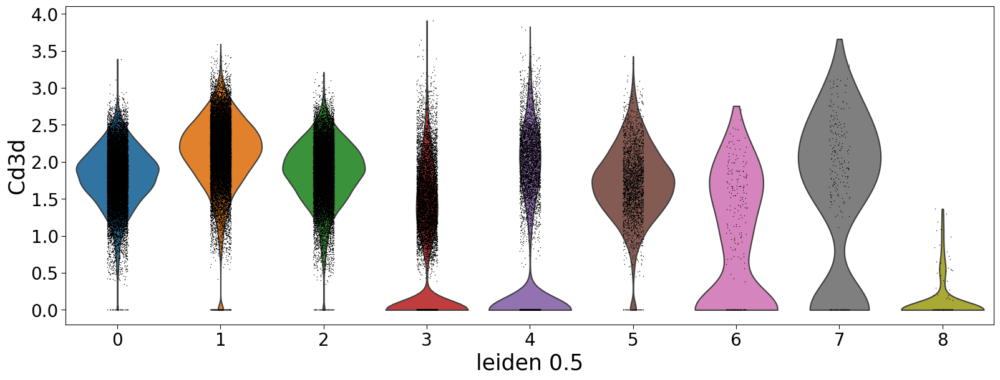

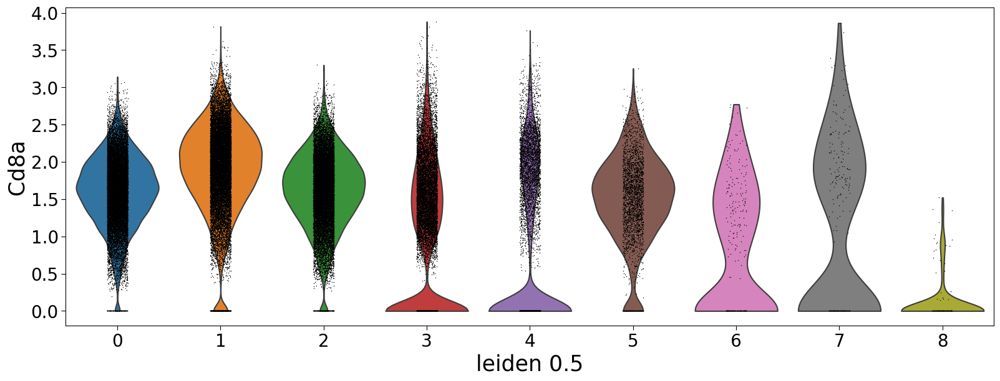

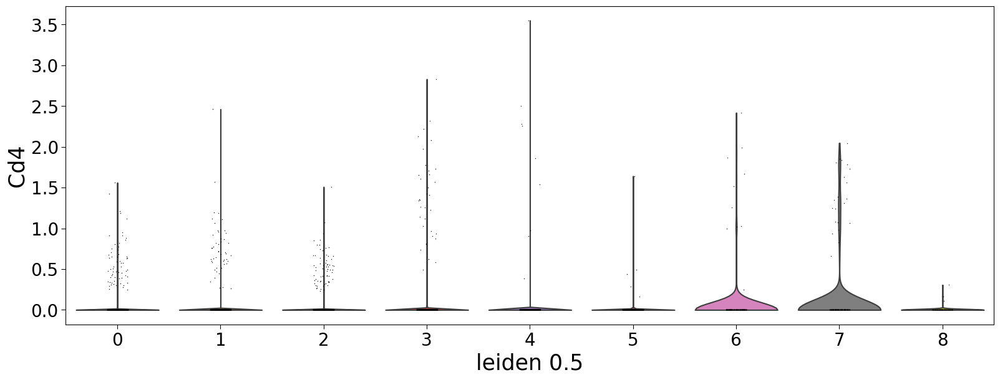

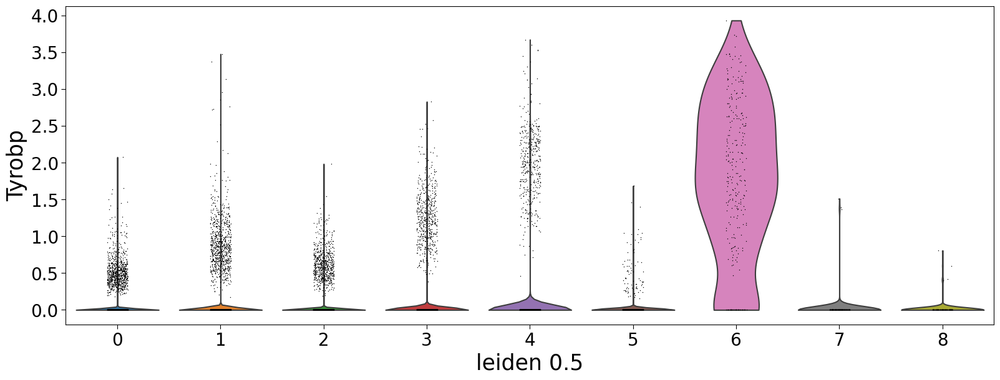

In [179]:
plt.rcParams['figure.figsize'] = (15,7)
for marker in ['Cd3d', 'Cd8a', 'Cd4', 'Tyrobp']:
    sc.pl.violin(adata, keys=[marker], groupby='leiden_0.5', layer='norm_log', use_raw=False)

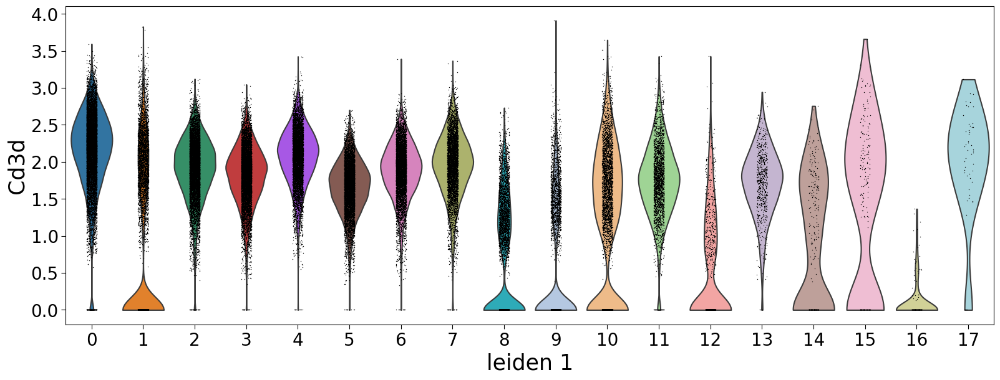

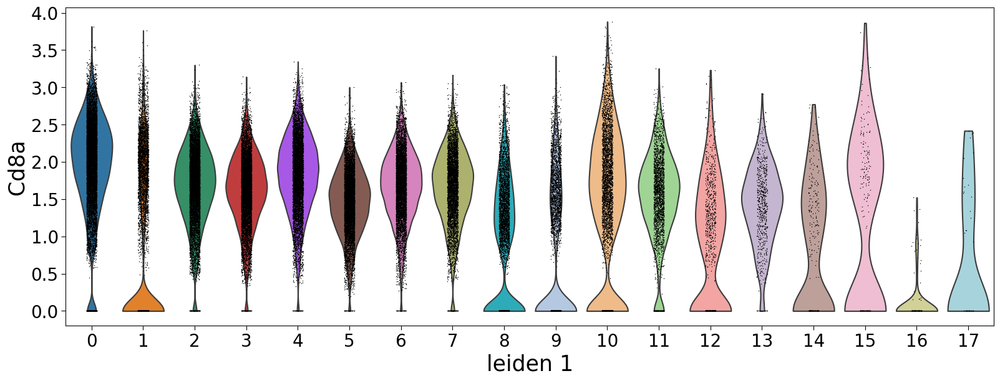

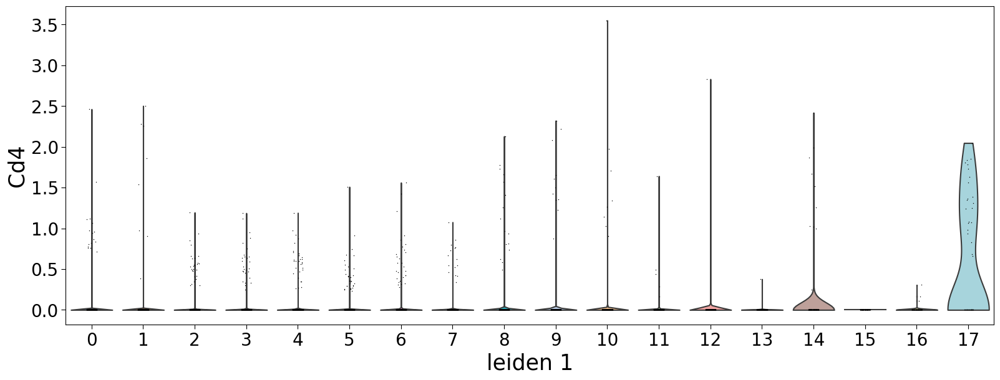

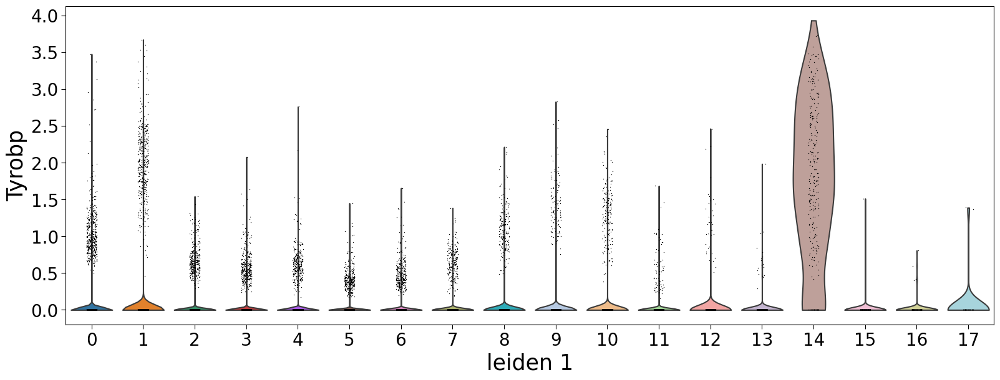

In [180]:
plt.rcParams['figure.figsize'] = (15,7)
for marker in ['Cd3d', 'Cd8a', 'Cd4', 'Tyrobp']:
    sc.pl.violin(adata, keys=[marker], groupby='leiden_1', layer='norm_log', use_raw=False)

In [184]:
cells_to_keep = adata[~adata.obs['leiden_1'].isin(['1', '12', '8', '9', '10', '14', '16', '17'])].obs_names

# Final Processing with Removed Cells

In [201]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/02_LP.h5ad")
adata = adata[adata.obs_names.isin(cells_to_keep)].copy()

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:843: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


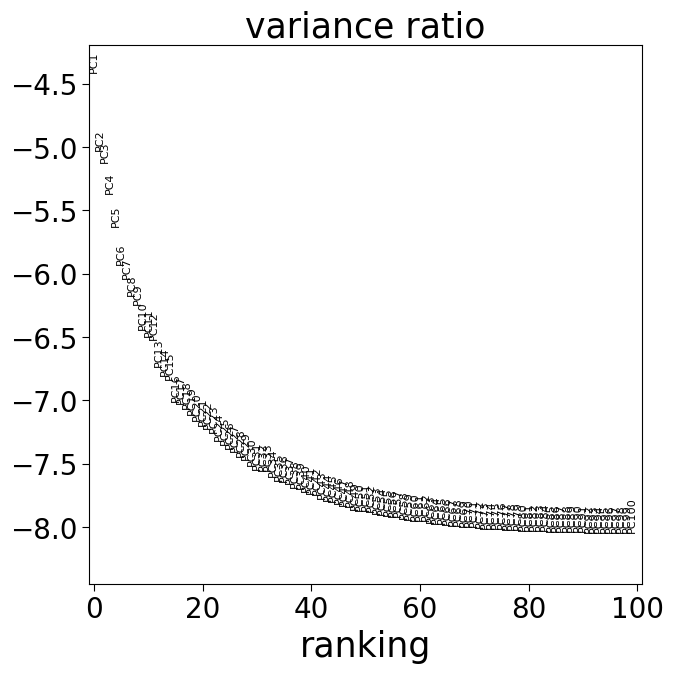

In [202]:
adata.raw = adata
adata.X = adata.X.toarray()
sc.pp.normalize_total(adata, exclude_highly_expressed=True)
adata.layers['norm'] = adata.X.copy()
sc.pp.log1p(adata)
adata.layers['norm_log'] = adata.X.copy()
sc.pp.highly_variable_genes(adata, n_top_genes=8000, flavor='seurat')
adata = adata[:, adata.var.highly_variable]
sc.pp.scale(adata, max_value=10)
adata.layers['norm_log_zscore'] = adata.X.copy()
sc.tl.pca(adata, svd_solver='arpack', n_comps=100)
sc.pl.pca_variance_ratio(adata, n_pcs=100, log=True)

In [203]:
adata = misc.my_score_cell_cycle_genes(adata)

In [204]:
plt.rcParams["axes.titlesize"] = 25
plt.rcParams["axes.labelsize"] = 25
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20
plt.rcParams["lines.markersize"] = 5
plt.rcParams['axes.grid'] = False
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['ytick.major.size'] = 5
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.title_fontsize'] = 15
plt.rcParams['legend.edgecolor'] = 'dimgray'
plt.rcParams['figure.figsize'] = (7,7)

10


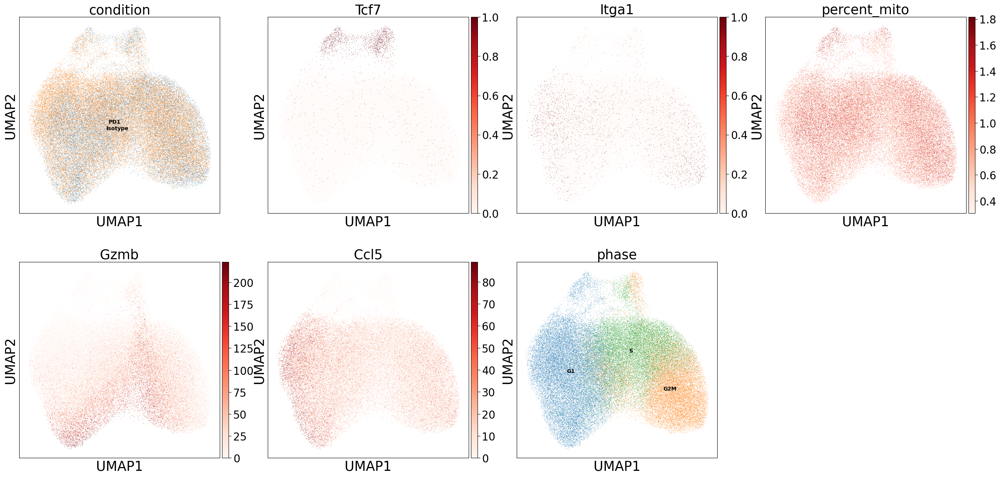

40


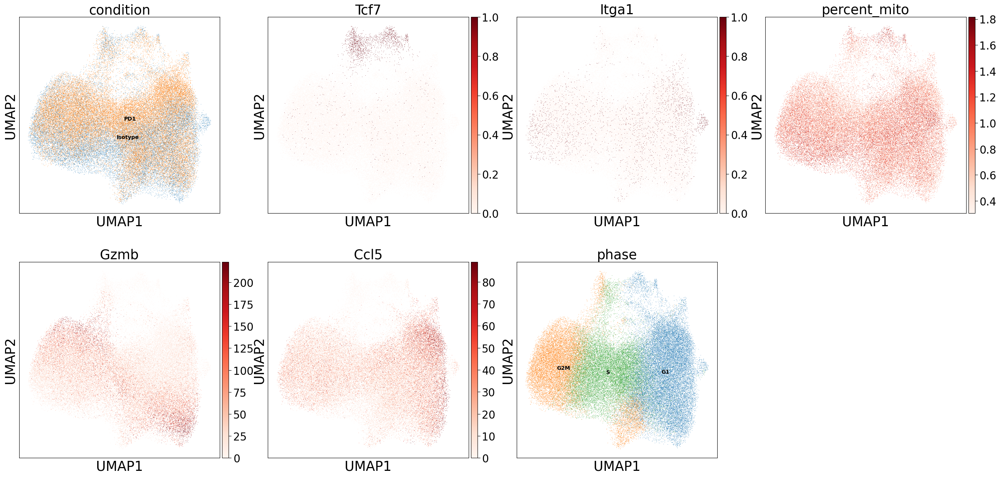

75


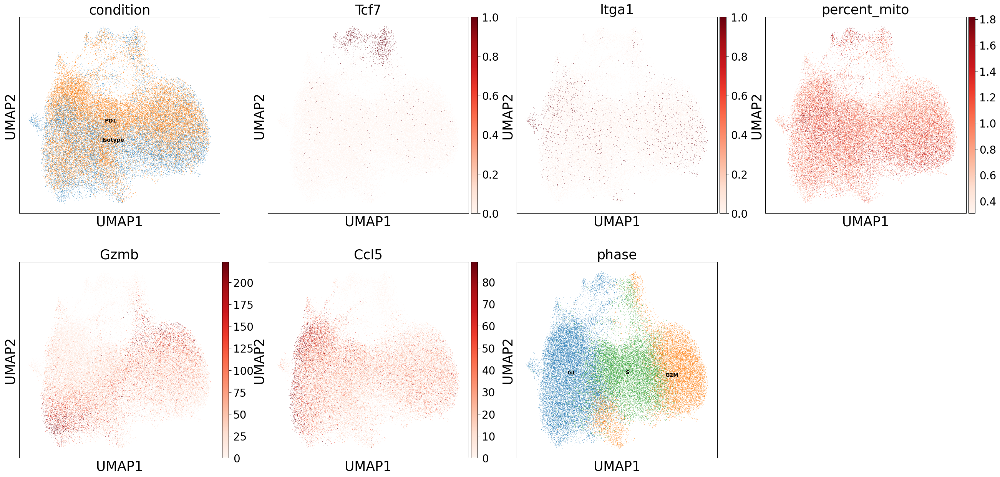

100


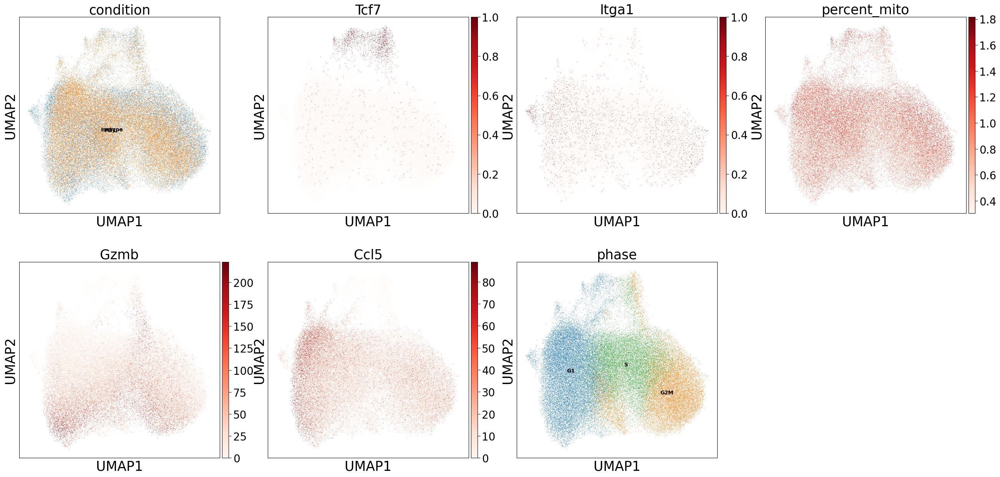

In [205]:
for i in [10, 40, 75, 100]:
    print(i)
    sc.pp.neighbors(adata, n_neighbors=20, n_pcs=i)
    sc.tl.umap(adata)

    sc.pl.umap(adata, color=['condition', 'Tcf7', 'Itga1', 'percent_mito', 'Gzmb', 'Ccl5', 'phase'],
               legend_loc='on data', cmap='Reds', vmin="p2", vmax="p98")

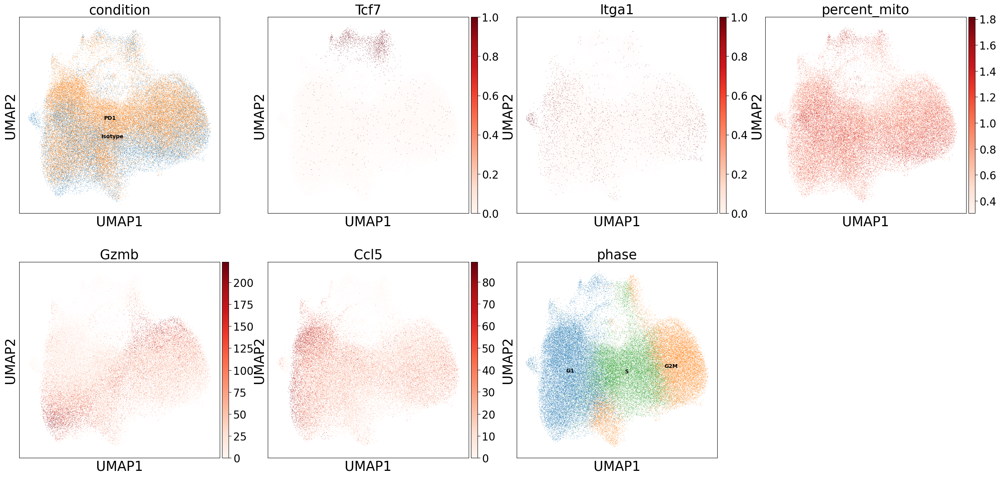

In [207]:
sc.pp.neighbors(adata, n_neighbors=20, n_pcs=50)
sc.tl.umap(adata)

sc.pl.umap(adata, color=['condition', 'Tcf7', 'Itga1', 'percent_mito', 'Gzmb', 'Ccl5', 'phase'],
           legend_loc='on data', cmap='Reds', vmin="p2", vmax="p98")

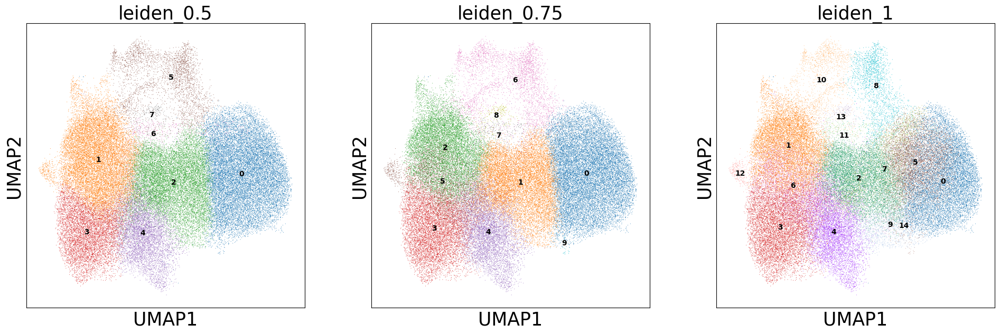

############################ leiden_0.5 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7


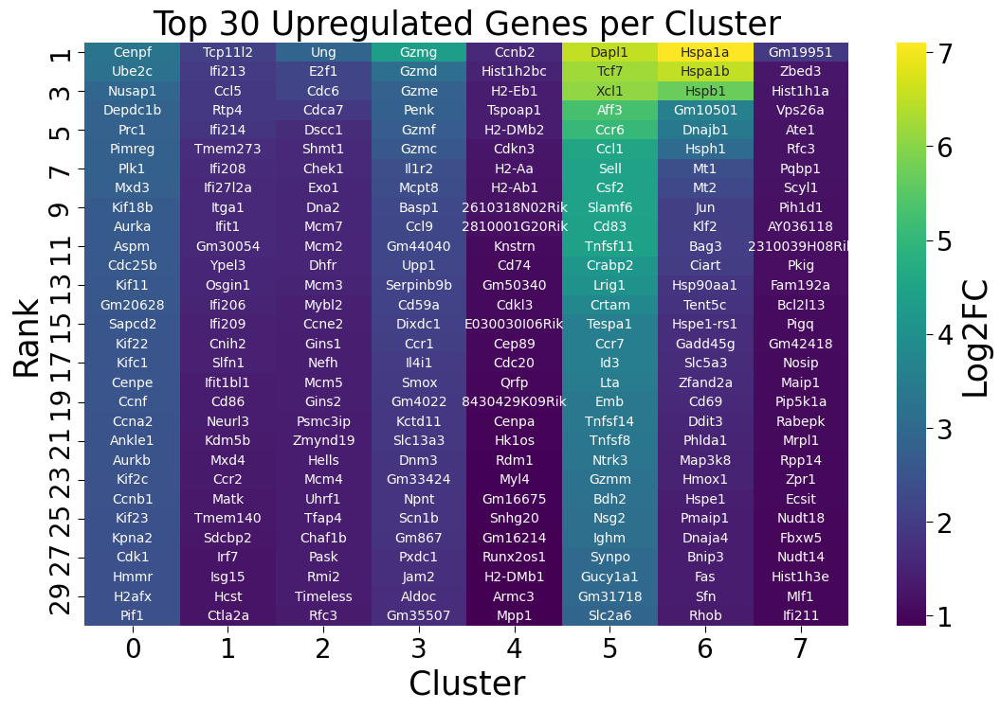

############################ leiden_0.75 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9


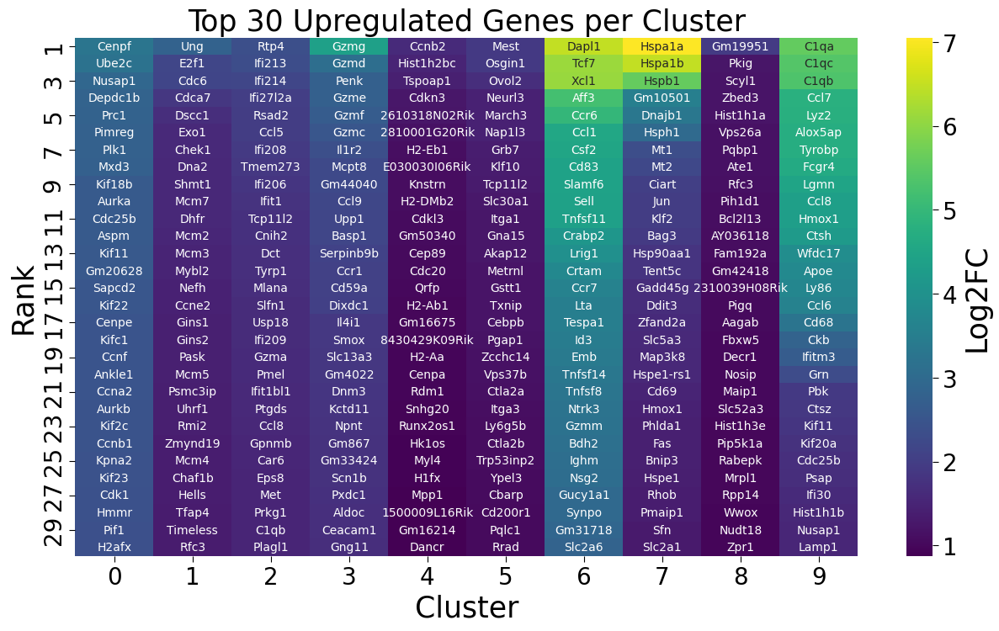

############################ leiden_1 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12
Processing cluster 13
Processing cluster 14


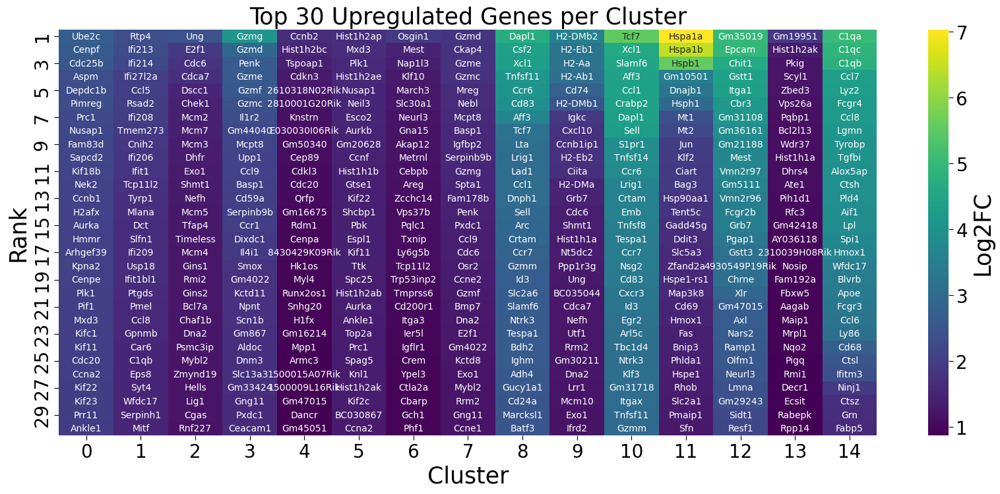

In [209]:
import DE_testing
reload(DE_testing)
all_de_results = DE_testing.apply_multi_resolution_clustering_then_heatmaps(adata, [0.5, 0.75, 1])

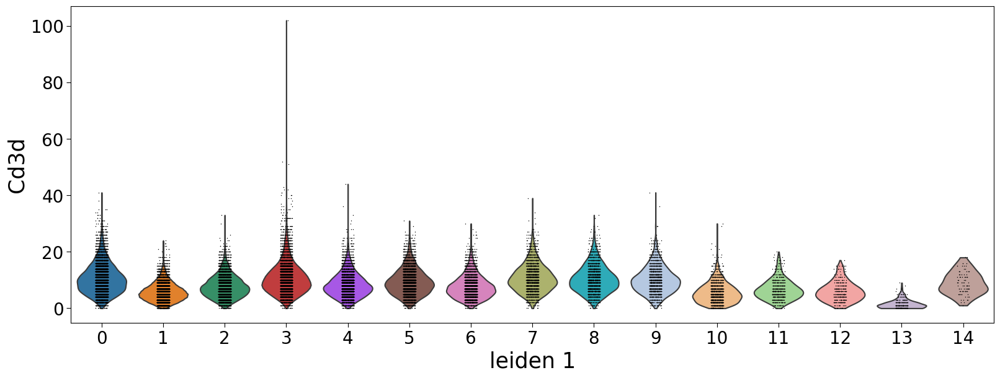

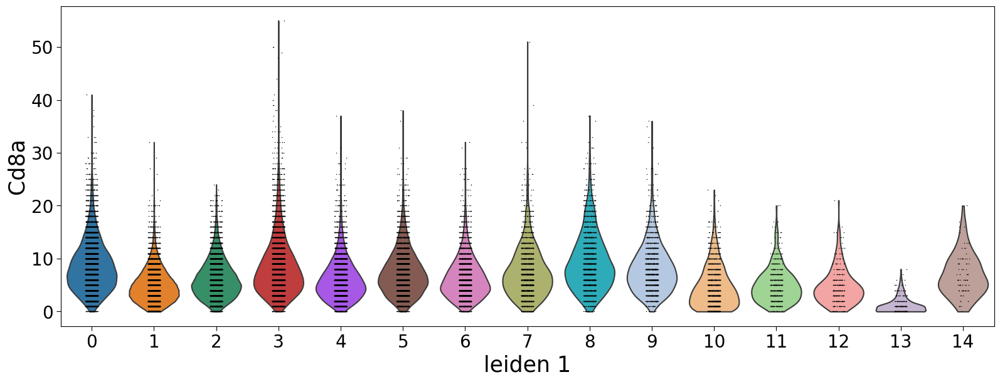

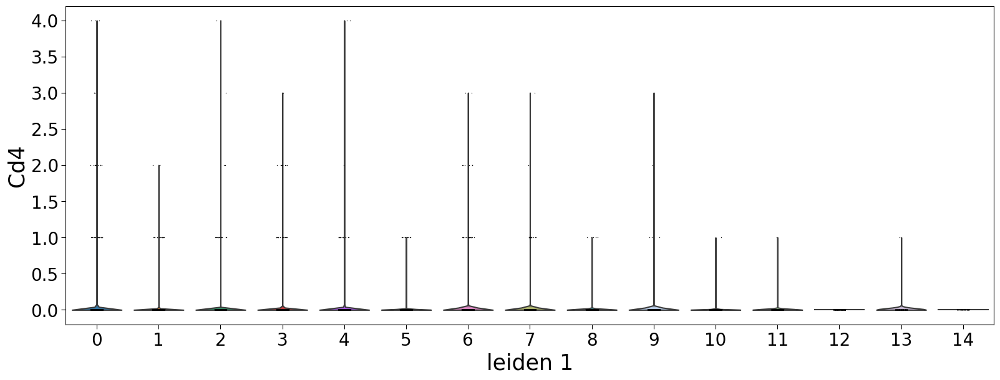

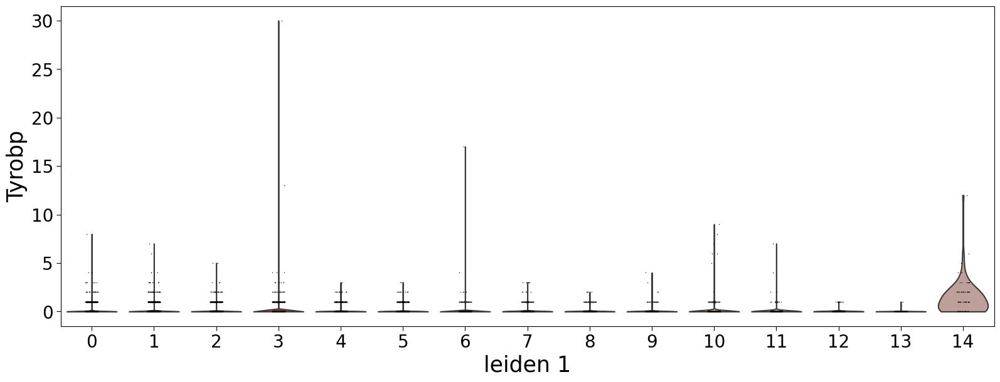

In [210]:
plt.rcParams['figure.figsize'] = (15,7)
for marker in ['Cd3d', 'Cd8a', 'Cd4', 'Tyrobp']:
    sc.pl.violin(adata, keys=[marker], groupby='leiden_1', use_raw=True)

In [211]:
# adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/04_filter_cells_adata.h5ad")

In [68]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/04_filter_cells_adata.h5ad")

In [212]:
cells_to_keep = adata[~adata.obs['leiden_1'].isin(['14'])].obs_names

# Round 2

In [224]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/02_LP.h5ad")
adata = adata[adata.obs_names.isin(cells_to_keep)].copy()

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:843: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


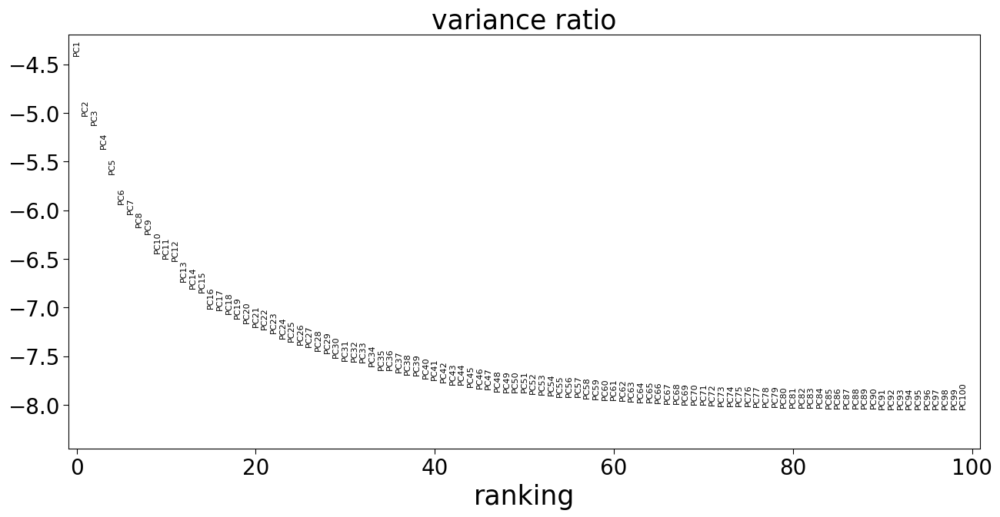

In [225]:
adata.raw = adata
adata.X = adata.X.toarray()
sc.pp.normalize_total(adata, exclude_highly_expressed=True)
adata.layers['norm'] = adata.X.copy()
sc.pp.log1p(adata)
adata.layers['norm_log'] = adata.X.copy()
sc.pp.highly_variable_genes(adata, n_top_genes=8000, flavor='seurat')
adata = adata[:, adata.var.highly_variable]
sc.pp.scale(adata, max_value=10)
adata.layers['norm_log_zscore'] = adata.X.copy()
sc.tl.pca(adata, svd_solver='arpack', n_comps=100)
sc.pl.pca_variance_ratio(adata, n_pcs=100, log=True)

In [226]:
adata = misc.my_score_cell_cycle_genes(adata)

In [227]:
plt.rcParams['figure.figsize'] = (7,7)

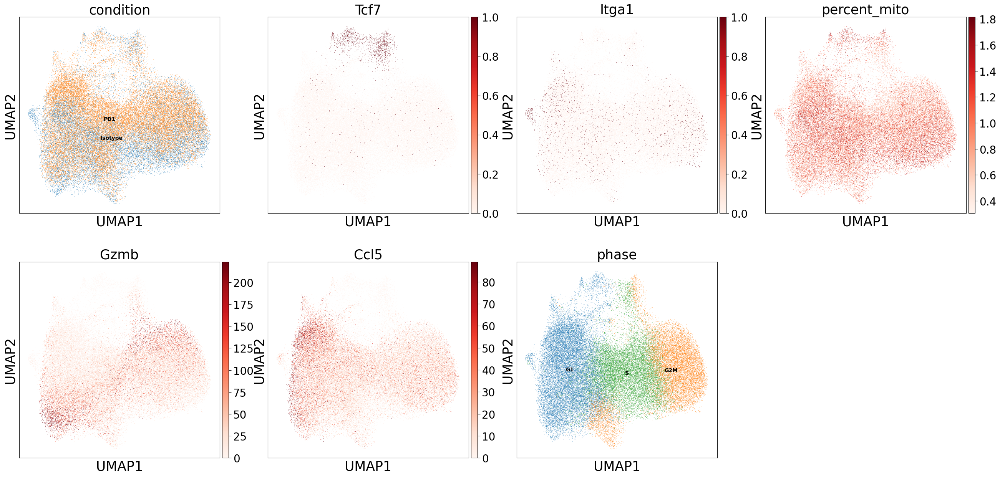

In [228]:
sc.pp.neighbors(adata, n_neighbors=20, n_pcs=50)
sc.tl.umap(adata)

sc.pl.umap(adata, color=['condition', 'Tcf7', 'Itga1', 'percent_mito', 'Gzmb', 'Ccl5', 'phase'],
           legend_loc='on data', cmap='Reds', vmin="p2", vmax="p98")

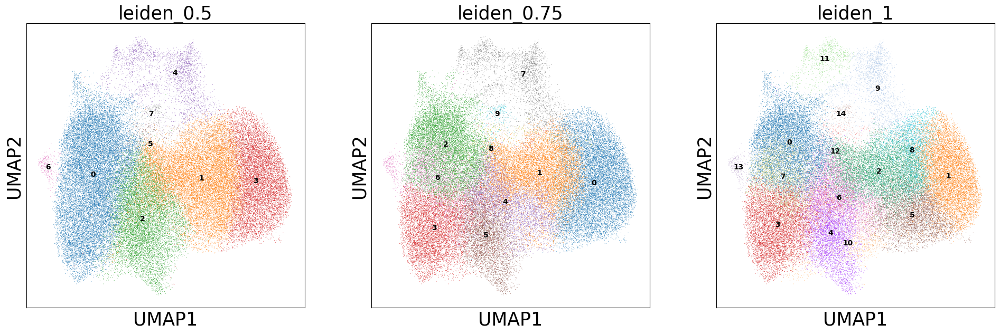

############################ leiden_0.5 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7


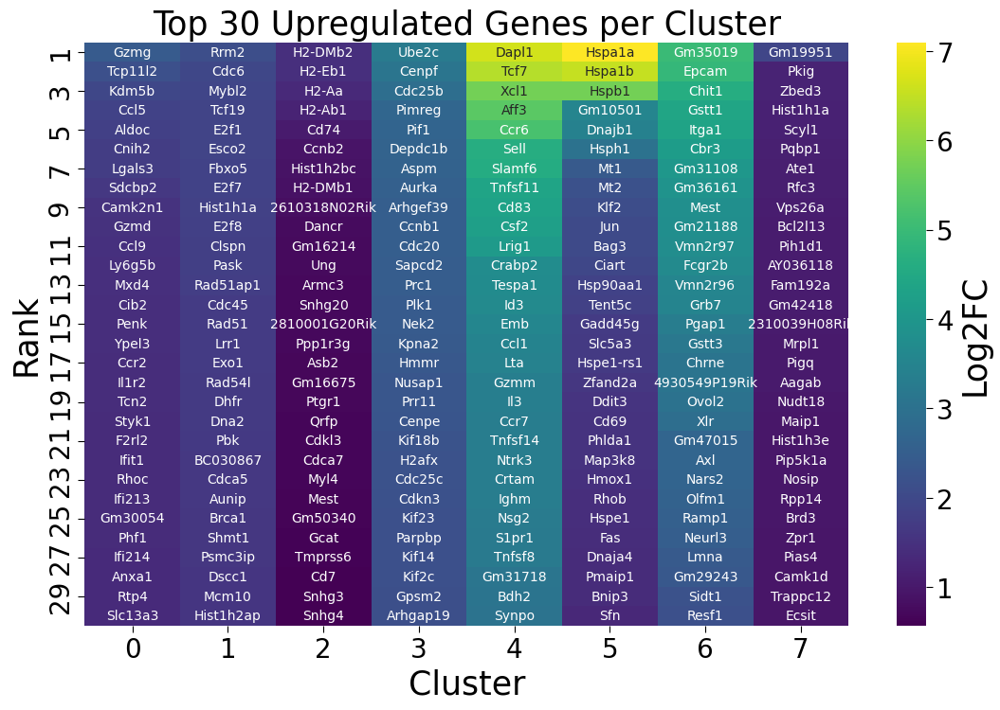

############################ leiden_0.75 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9


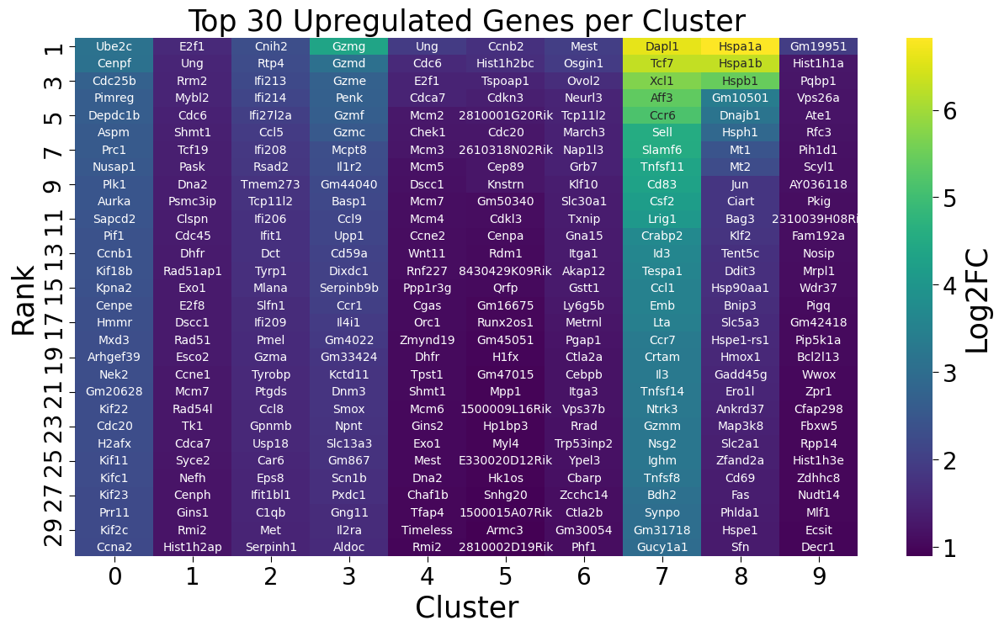

############################ leiden_1 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12
Processing cluster 13
Processing cluster 14


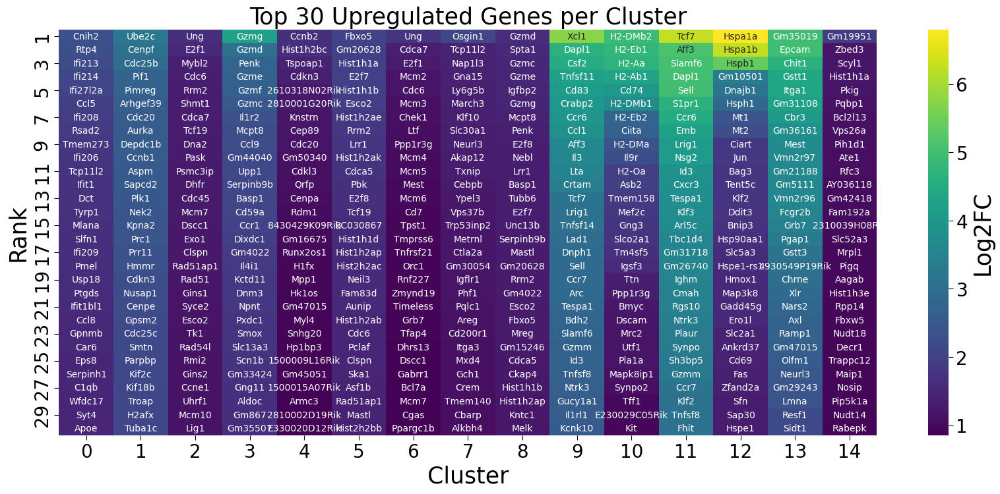

In [229]:
import DE_testing
reload(DE_testing)
all_de_results = DE_testing.apply_multi_resolution_clustering_then_heatmaps(adata, [0.5, 0.75, 1])

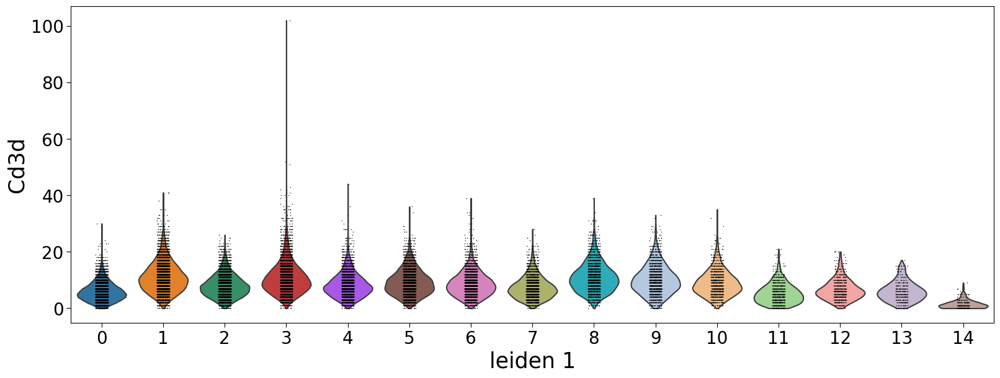

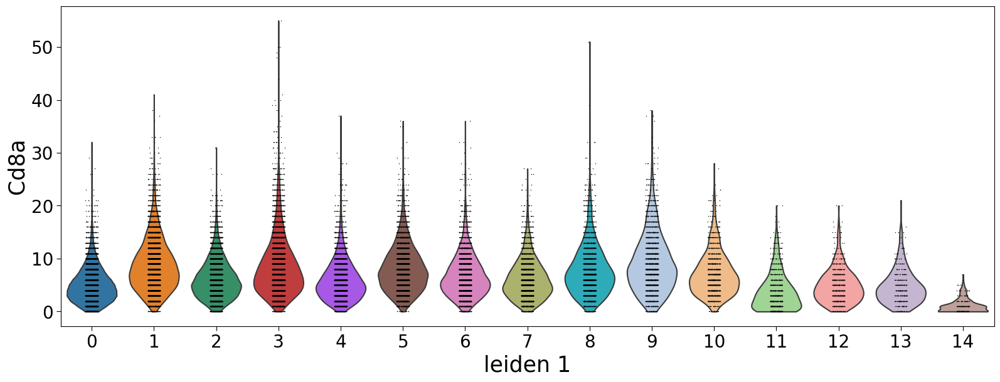

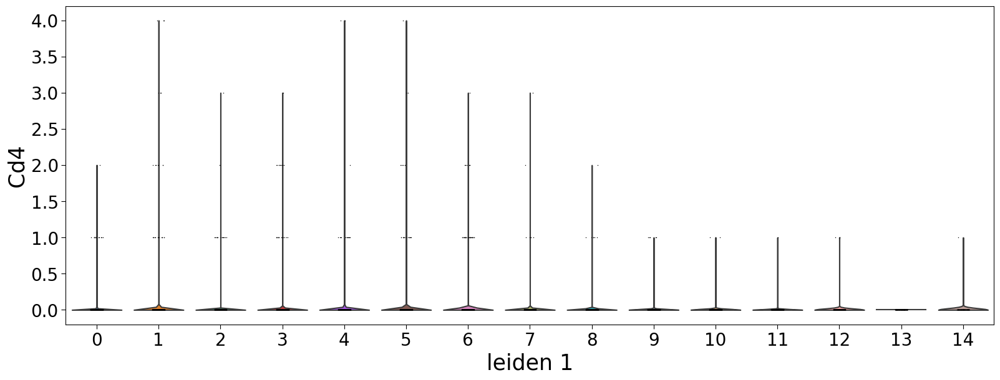

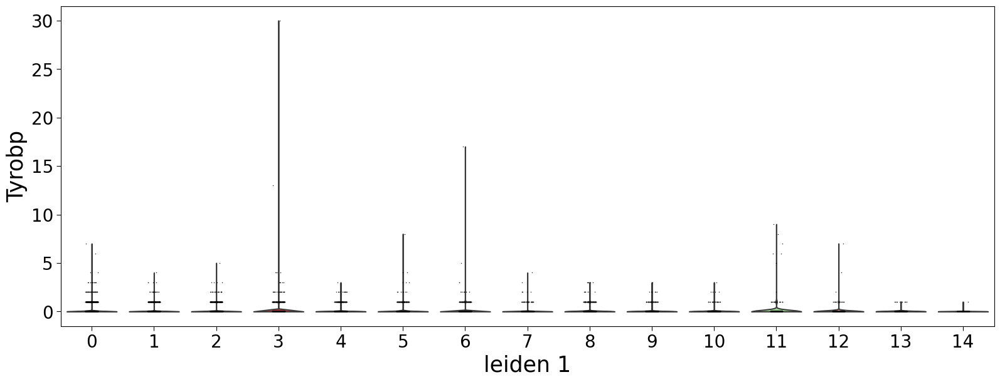

In [230]:
plt.rcParams['figure.figsize'] = (15,7)
for marker in ['Cd3d', 'Cd8a', 'Cd4', 'Tyrobp']:
    sc.pl.violin(adata, keys=[marker], groupby='leiden_1', use_raw=True)

In [231]:
# adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/05_filter_cells_adata.h5ad")

In [245]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/05_filter_cells_adata.h5ad")

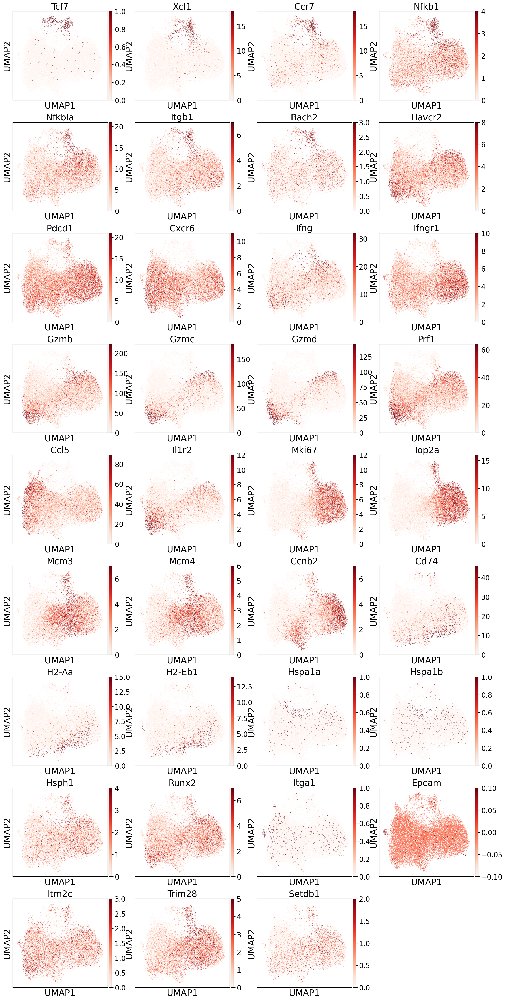

In [246]:
plt.rcParams['figure.figsize'] = (5,5)
sc.pl.umap(adata, color=['Tcf7',  'Xcl1', 'Ccr7', 'Nfkb1', 'Nfkbia', 'Itgb1', 'Bach2',
                        'Havcr2', 'Pdcd1', 'Cxcr6', 'Ifng', 'Ifngr1',
                      'Gzmb', 'Gzmc', 'Gzmd', 'Prf1',
                      'Ccl5',
                      'Il1r2',
                      'Mki67','Top2a', 'Mcm3', 'Mcm4', 'Ccnb2',
                      'Cd74', 'H2-Aa', 'H2-Eb1',
                      'Hspa1a', 'Hspa1b', 'Hsph1',
                      'Runx2',
                      'Itga1', 'Epcam', 'Itm2c',
                     'Trim28', 'Setdb1'], color_map='Reds', vmin='p2', vmax='p98')

In [247]:
def get_cell_type(r):
    leiden05 = r['leiden_0.5']
    leiden075 = r['leiden_0.75']
    leiden1 = r['leiden_1']
    cell_type = None
    if leiden1 == '9':
        cell_type = 'Progenitor Cycling'
    if leiden1 == '11':
        cell_type = 'Progenitor'
    if leiden1 == '13':
        cell_type = 'TRM-like'
    if leiden1 == '0' or leiden1 == '7':
        cell_type = 'Ccl5+'
    if leiden1 == '3':
        cell_type = 'Granzyme High'
    if leiden1 == '14':
        cell_type = 'Ccl5+'
    if cell_type:
        return cell_type
    else:
        return 'Cycling'

adata.obs['cell_type'] = adata.obs.apply(get_cell_type, axis=1)

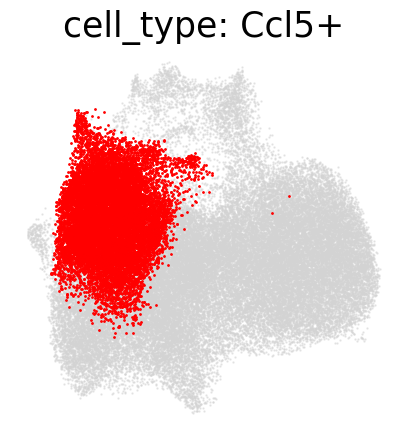

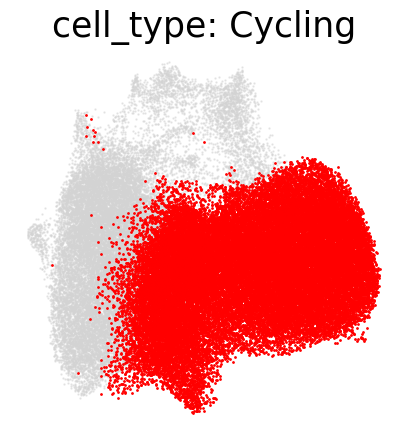

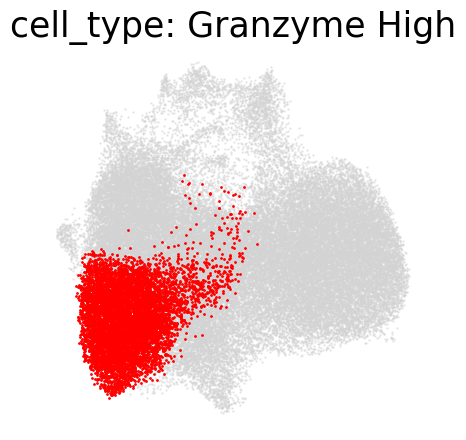

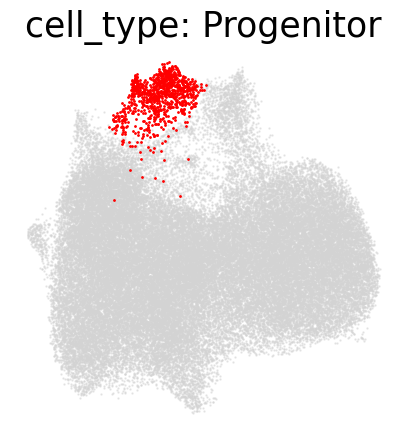

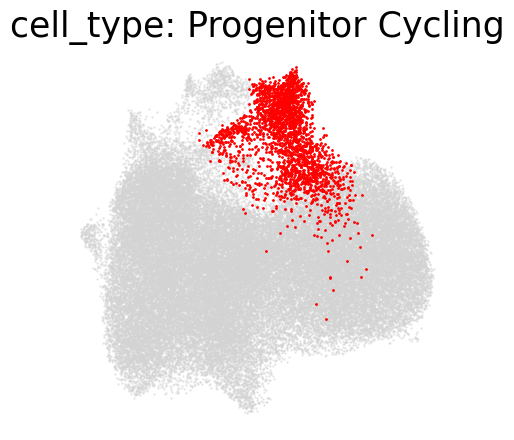

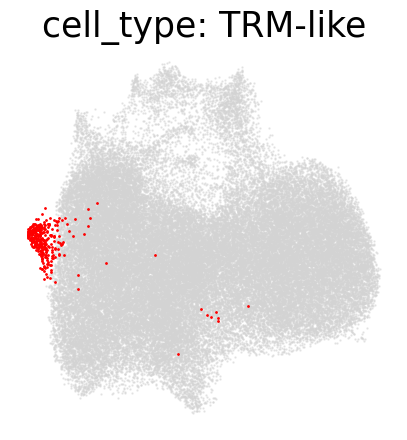

In [248]:
reload(misc)
for cell_type in np.unique(adata.obs['cell_type']):
    misc.draw_overlap_umap(adata, 'cell_type', cell_type, 'red', size=0.5)

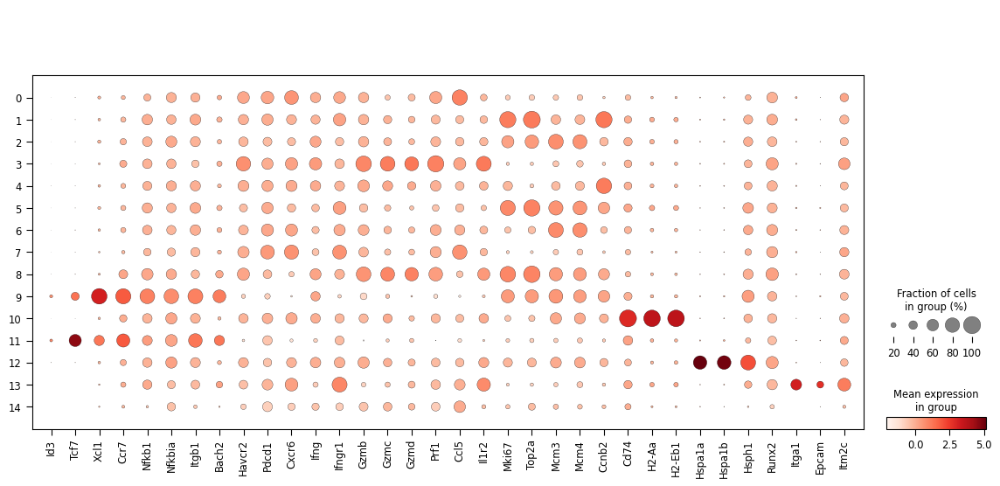

In [249]:
sc.pl.dotplot(adata, ['Id3', 'Tcf7',  'Xcl1', 'Ccr7', 'Nfkb1', 'Nfkbia', 'Itgb1', 'Bach2',
                        'Havcr2', 'Pdcd1', 'Cxcr6', 'Ifng', 'Ifngr1',
                      'Gzmb', 'Gzmc', 'Gzmd', 'Prf1',
                      'Ccl5',
                      'Il1r2',
                      'Mki67','Top2a', 'Mcm3', 'Mcm4', 'Ccnb2',
                      'Cd74', 'H2-Aa', 'H2-Eb1',
                      'Hspa1a', 'Hspa1b', 'Hsph1',
                      'Runx2',
                      'Itga1', 'Epcam', 'Itm2c'],
              layer='norm_log_zscore',
              groupby='leiden_1',
              dendrogram=False)

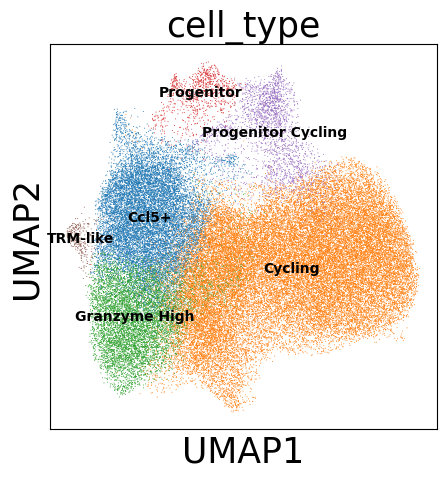

In [250]:
sc.pl.umap(adata, color=['cell_type'],
           legend_loc='on data', cmap='Reds', vmin="p2", vmax="p98")

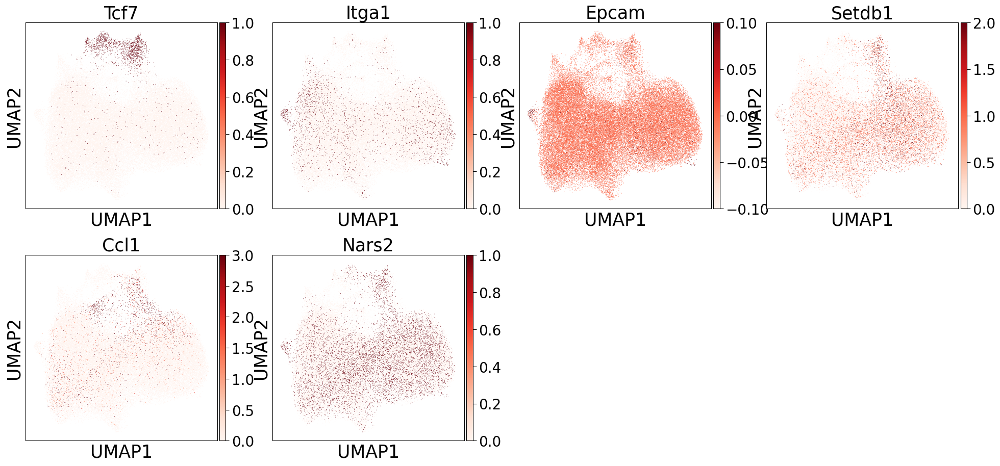

In [251]:
plt.rcParams['figure.figsize'] = (5,5)
sc.pl.umap(adata, color=['Tcf7',
                      'Itga1', 'Epcam', 'Setdb1', 'Ccl1', 'Nars2'], color_map='Reds', vmin='p2', vmax='p98')

In [252]:
adata.obs

,lane,percent_mito,HTO_classification.global,hashtag,condition,hashtag_number,mouse,all_constructs_str,num_constructs,cat_num_constructs,...,perturbation,clone,S_score,G2M_score,phase,leiden,leiden_0.5,leiden_0.75,leiden_1,cell_type
lane1_AAACCTGAGAGATGAG-1,lane1,0.734476,Singlet,Hashtag5,Isotype,5,Isotype_Hashtag5,NO_SITE-1__CAACCA,1,One,...,NT,Isotype_Hashtag5|NO_SITE_26__CAACCA,-0.388939,0.347499,G2M,4,2,5,4,Cycling
lane1_AAACCTGAGCAGGTCA-1,lane1,2.311993,Singlet,Hashtag4,Isotype,4,Isotype_Hashtag4,,0,Zero,...,,,-0.019480,0.562697,G2M,1,3,0,1,Cycling
lane1_AAACCTGCACCCTATC-1,lane1,0.631662,Singlet,Hashtag5,Isotype,5,Isotype_Hashtag5,Ifngr1-1__GACGTT,1,One,...,Ifngr1,Isotype_Hashtag5|Ifngr1-1__GACGTT,-0.741827,-0.854646,G1,3,0,3,3,Granzyme High
lane1_AAACCTGCATTTGCTT-1,lane1,1.222278,Singlet,Hashtag5,Isotype,5,Isotype_Hashtag5,NO_SITE-1__CAACCA,1,One,...,NT,Isotype_Hashtag5|NO_SITE_26__CAACCA,-0.458845,-0.555798,G1,3,0,3,3,Granzyme High
lane1_AAACCTGGTAAACGCG-1,lane1,1.417004,Singlet,Hashtag3,Isotype,3,Isotype_Hashtag3,Ifngr1-1__CCATAG,1,One,...,Ifngr1,Isotype_Hashtag3|Ifngr1-1__CCATAG,-0.592954,-0.608047,G1,7,0,6,7,Ccl5+
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
lane8_TTTGTCATCCTGCAGG-1,lane8,0.714201,Singlet,Hashtag3,PD1,3,PD1_Hashtag3,Il18r1-1__CGAGTA,1,One,...,Il18r1,PD1_Hashtag3|Il18r1-1__CGAGTA,0.066909,0.276844,G2M,2,1,1,2,Cycling
lane8_TTTGTCATCGGAAACG-1,lane8,0.558479,Singlet,Hashtag3,PD1,3,PD1_Hashtag3,,0,Zero,...,,,-0.290505,0.669363,G2M,1,1,0,1,Cycling
lane8_TTTGTCATCGTTGCCT-1,lane8,0.355661,Singlet,Hashtag2,PD1,2,PD1_Hashtag2,INTERGENIC-1__CGGGCG,1,One,...,NT,PD1_Hashtag2|ONE_INTERGENIC_SITE_1__CGGGCG,1.036779,-0.076467,S,2,1,1,2,Cycling
lane8_TTTGTCATCTCAAGTG-1,lane8,1.207243,Singlet,Hashtag3,PD1,3,PD1_Hashtag3,INTERGENIC-3__AGACTT,1,One,...,NT,PD1_Hashtag3|ONE_INTERGENIC_SITE_5__AGACTT,0.357550,-0.359642,S,6,2,4,6,Cycling


In [253]:
adata.obs = adata.obs.drop(columns = ['leiden', 'leiden_0.5', 'leiden_0.75', 'leiden_1'])

In [4]:
# adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/before_final.h5ad")

## Change some columns

In [15]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/before_final.h5ad")

In [16]:
import pandas as pd
import scanpy as sc

# Assuming your adata object is already loaded and available

# Extract the unique mouse identifiers
unique_mice = adata.obs['mouse'].unique()

# Create dictionaries to map old identifiers to new names
pd1_counter = 1  # Starting number for PD-1
iso_counter = 1  # Starting number for Isotype
mouse_mapping = {}

for mouse in unique_mice:
    if 'PD1' in mouse:
        new_name = f"aPD1:{pd1_counter}"
        mouse_mapping[mouse] = new_name
        pd1_counter += 1
    elif 'Isotype' in mouse:
        new_name = f"Isotype:{iso_counter}"
        mouse_mapping[mouse] = new_name
        iso_counter += 1

# Map the old mouse identifiers to the new names
adata.obs['mouse'] = adata.obs['mouse'].map(mouse_mapping)

# Verify the changes
print(adata.obs['mouse'].value_counts())

Isotype:3    8792
aPD1:1       8260
aPD1:2       7983
aPD1:3       7617
Isotype:1    6796
aPD1:6       6311
Isotype:2    4966
aPD1:7       4093
aPD1:4       2346
Isotype:5    2225
Isotype:6     394
aPD1:5        346
Isotype:4     300
aPD1:8        132
Isotype:7      60
Name: mouse, dtype: int64


In [17]:
adata.obs['mouse']

lane1_AAACCTGAGAGATGAG-1    Isotype:1
lane1_AAACCTGAGCAGGTCA-1    Isotype:2
lane1_AAACCTGCACCCTATC-1    Isotype:1
lane1_AAACCTGCATTTGCTT-1    Isotype:1
lane1_AAACCTGGTAAACGCG-1    Isotype:3
                              ...    
lane8_TTTGTCATCCTGCAGG-1       aPD1:1
lane8_TTTGTCATCGGAAACG-1       aPD1:1
lane8_TTTGTCATCGTTGCCT-1       aPD1:3
lane8_TTTGTCATCTCAAGTG-1       aPD1:1
lane8_TTTGTCATCTGCTGTC-1       aPD1:7
Name: mouse, Length: 60621, dtype: category
Categories (15, object): ['Isotype:4', 'Isotype:7', 'Isotype:3', 'Isotype:2', ..., 'aPD1:8', 'aPD1:5', 'aPD1:4', 'aPD1:2']

In [18]:
def assign_clone(row):
    if row['all_constructs_str'] == '':
        return ''
    else:
        return f"{row['mouse']}|{row['all_constructs_str']}"

# Apply the function across the rows
adata.obs['clone'] = adata.obs.apply(assign_clone, axis=1)

# Step 2: Update 'clone_size'
clone_size = adata.obs.groupby('clone').size()
adata.obs['clone_size'] = adata.obs['clone'].map(clone_size)

In [19]:
adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/final.h5ad")